In [1]:
# !pip install -r requirements.txt

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

# Prepare data

In [3]:
image_paths = glob.glob('./data/*.jpg')
json_paths = [pth.replace('jpg', 'json') for pth in image_paths]
image_paths, json_paths

(['./data/006_IT158412_1.jpg',
  './data/008_IT158764_1.jpg',
  './data/009_IT221893_1.jpg',
  './data/010_IT223741_1.jpg',
  './data/001_IT135673_1.jpg',
  './data/004_IT158286_1.jpg',
  './data/003_IT158279_1.jpg',
  './data/011_IT223788_1.jpg',
  './data/012_IT225004_1.jpg'],
 ['./data/006_IT158412_1.json',
  './data/008_IT158764_1.json',
  './data/009_IT221893_1.json',
  './data/010_IT223741_1.json',
  './data/001_IT135673_1.json',
  './data/004_IT158286_1.json',
  './data/003_IT158279_1.json',
  './data/011_IT223788_1.json',
  './data/012_IT225004_1.json'])

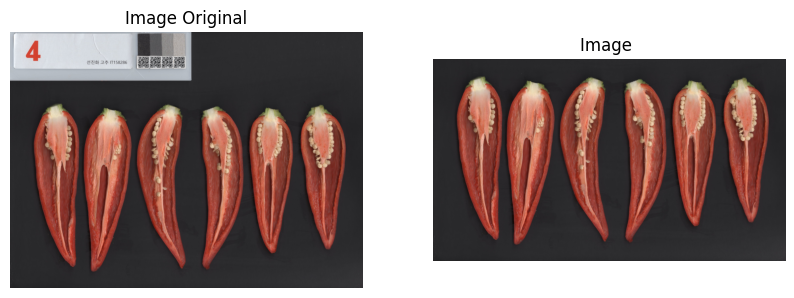

In [4]:
image = cv2.imread(image_paths[5])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_crop = image_RGB[540:, :, :]

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(image_RGB)
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_crop)
plt.title("Image ")
plt.axis("off")

plt.show()

# Get Bbox

### Detect bbox by threshold

In [5]:
# from segment import SegmentModel
from src.detect import DetectModel

model_detect = DetectModel(model_name='none')
# model_detect.predict(image_paths[0])

Use threshold for detect each chili fruit


In [6]:
path = image_paths[5]
masks = model_detect.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"runs/detect/predict/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

### Detect chili by model YOLO

- chưa load được model gọn nhẹ

# Segment for each chili

In [7]:
from src.segment import SegmentModel

model_seg = SegmentModel(weight_path='./pretrain/yolov8_segment_v1.pt', model_name='yolo')

In [8]:
import glob

img_paths = glob.glob('./runs/detect/predict/*.jpg')
imgs = [cv2.imread(path) for path in img_paths]
RGB_imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imgs]

results = model_seg.predict(RGB_imgs[0])

r = results['raw_results'][0]  # first image result


0: 640x224 12 seeds, 1 placenta, 1 endocarp, 210.7ms
Speed: 1.7ms preprocess, 210.7ms inference, 49.8ms postprocess per image at shape (1, 3, 640, 224)


In [9]:
[i['class_name'] for i in results['polygons']]

['placenta',
 'endocarp',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed',
 'seed']

In [10]:
names = r.names
masks = r.masks.data
polygons = r.masks.xy
xyxy = r.boxes.xyxy      # (N,4)
cls  = r.boxes.cls
conf = r.boxes.conf

In [11]:
masks.shape

torch.Size([14, 1726, 551])

# Test pipeline


0: 640x224 13 seeds, 1 placenta, 1 endocarp, 190.3ms
Speed: 13.6ms preprocess, 190.3ms inference, 48.0ms postprocess per image at shape (1, 3, 640, 224)
0 [238, 715, 451, 1626]

0: 640x224 6 seeds, 1 placenta, 1 endocarp, 176.7ms
Speed: 13.6ms preprocess, 176.7ms inference, 29.6ms postprocess per image at shape (1, 3, 640, 224)
1 [735, 755, 473, 1633]

0: 640x224 23 seeds, 1 placenta, 1 endocarp, 156.4ms
Speed: 1.0ms preprocess, 156.4ms inference, 86.7ms postprocess per image at shape (1, 3, 640, 224)
2 [1263, 722, 485, 1636]

0: 640x192 19 seeds, 1 placenta, 1 endocarp, 202.1ms
Speed: 10.9ms preprocess, 202.1ms inference, 71.4ms postprocess per image at shape (1, 3, 640, 192)
3 [1902, 742, 418, 1624]

0: 640x224 18 seeds, 1 placenta, 1 endocarp, 156.1ms
Speed: 1.1ms preprocess, 156.1ms inference, 57.2ms postprocess per image at shape (1, 3, 640, 224)
4 [2381, 754, 433, 1452]

0: 640x256 27 seeds, 1 placenta, 1 endocarp, 182.8ms
Speed: 1.8ms preprocess, 182.8ms inference, 72.3ms postp

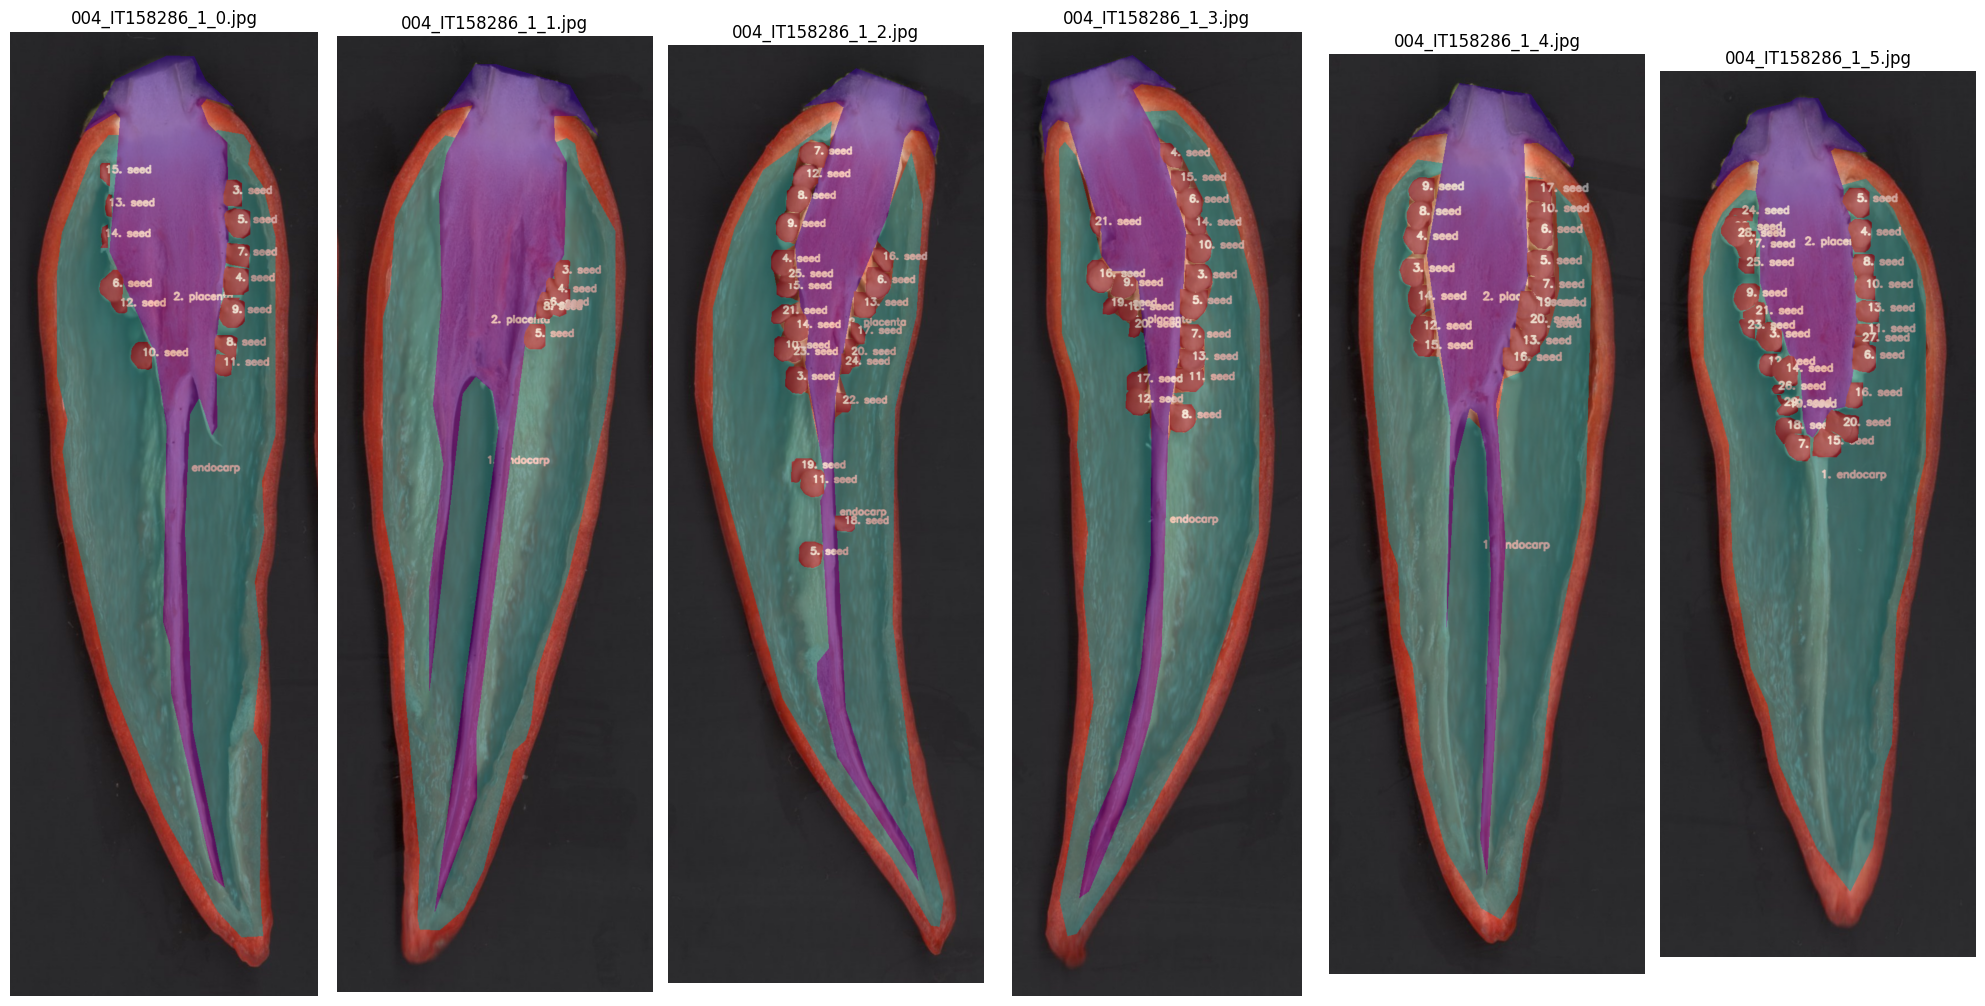

In [19]:
from src.object import Fruits
from PIL import Image

fruits = Fruits('/home/lap15692/Downloads/code/chili_paper/chili_segment/data/004_IT158286_1.jpg', model_detect, model_seg)
imgs = fruits.show()

for i in range(len(imgs)):
    # cv2.imwrite(f"runs/segment/predict/output_{i}.jpg", imgs[i])
    Image.fromarray(imgs[i]).save(f"runs/segment/predict/output_{i}.jpg")
# fruits.items[0].rseg

In [13]:
fruits.items[0].rseg['raw_results'][0].masks.xy[0]
fruits.items[0].polygons[0].keys()

dict_keys(['class_id', 'class_name', 'points', 'points_normalized'])

[188, 739, 665, 2391]
[685, 1258, 705, 2438]
[1213, 1798, 672, 2408]
[1852, 2370, 692, 2416]
[2331, 2864, 704, 2256]
[2841, 3390, 679, 2218]


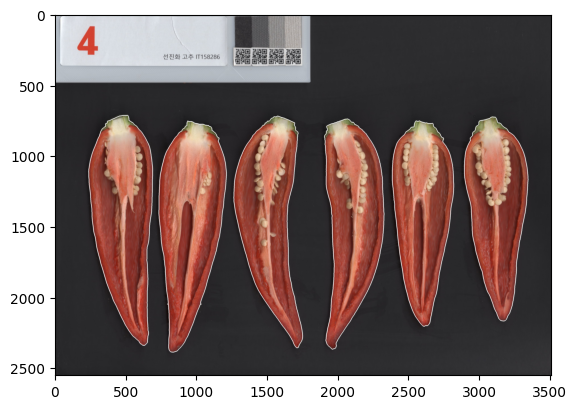

In [14]:
image = fruits.image.copy()
image = np.array(image)
for chili in fruits.items:
    contour, img =chili.get_contour()
    pos = chili.position
    print(pos)
    for i in range(len(contour[0])):
        contour[0][i][0][0] = contour[0][i][0][0] + pos[0]
        contour[0][i][0][1] = contour[0][i][0][1] + pos[2]
        # print(contour[0][i][0])
        # break
    cv2.drawContours(image, contour, -1, (255, 255, 255), 3)
    # chili.position
    # break
plt.imshow(image)
plt.show()

In [15]:
# !python predict.py --input_path ./data/ --name_model_seg yolo --weight_seg ./pretrain/yolov8_segment_v1.pt --save_csv

# Accuracy

# App demo